In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
baseball = pd.read_csv("cleaned_batting_stats.csv")
cleaned_baseball = baseball.copy()

In [3]:
cleaned_baseball.head(5)

,Rk,Player,Age,Team,Lg,WAR,G,PA,AB,R,...,TB,GIDP,HBP,SH,SF,IBB,Pos,Awards,Year,RowNum
0,357.0,A.J. Ellis,35.0,2TM,NL,-0.1,64.0,196.0,171.0,11.0,...,51.0,5.0,2.0,3.0,1.0,2.0,2/H,NaN,2016,1
1,416.0,AJ Pollock,35.0,2TM,2LG,-0.7,54.0,144.0,133.0,15.0,...,41.0,1.0,0.0,0.0,2.0,0.0,7DH/89,NaN,2023,1
2,284.0,Aaron Hicks#,33.0,2TM,AL,0.5,93.0,312.0,269.0,44.0,...,103.0,3.0,0.0,0.0,1.0,1.0,879H/D,NaN,2023,1
3,193.0,Aaron Hill,34.0,2TM,2LG,1.5,125.0,429.0,378.0,48.0,...,143.0,6.0,3.0,0.0,4.0,2.0,54H/D,NaN,2016,1
4,301.0,Abraham Almonte#,26.0,2TM,2LG,0.8,82.0,258.0,232.0,36.0,...,95.0,5.0,0.0,3.0,2.0,0.0,8H/79D,NaN,2015,1


In [4]:
cleaned_baseball.columns

Index(['Rk', 'Player', 'Age', 'Team', 'Lg', 'WAR', 'G', 'PA', 'AB', 'R', 'H',
       '2B', '3B', 'HR', 'RBI', 'SB', 'CS', 'BB', 'SO', 'BA', 'OBP', 'SLG',
       'OPS', 'OPS+', 'rOBA', 'Rbat+', 'TB', 'GIDP', 'HBP', 'SH', 'SF', 'IBB',
       'Pos', 'Awards', 'Year', 'RowNum'],
      dtype='str')

In [5]:
cleaned_baseball.dtypes

Rk        float64
Player        str
Age       float64
Team          str
Lg            str
WAR       float64
G         float64
PA        float64
AB        float64
R         float64
H         float64
2B        float64
3B        float64
HR        float64
RBI       float64
SB        float64
CS        float64
BB        float64
SO        float64
BA        float64
OBP       float64
SLG       float64
OPS       float64
OPS+      float64
rOBA      float64
Rbat+     float64
TB        float64
GIDP      float64
HBP       float64
SH        float64
SF        float64
IBB       float64
Pos           str
Awards        str
Year        int64
RowNum      int64
dtype: object

**data cleaning**
<br>drop columns of Rk and RowNum</br>

In [6]:
cleaned_baseball = cleaned_baseball.drop(columns=["Rk", "RowNum", "Pos"])
cleaned_baseball

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB,Awards,Year
0,A.J. Ellis,35.0,2TM,NL,-0.1,64.0,196.0,171.0,11.0,37.0,...,0.279,62.0,51.0,5.0,2.0,3.0,1.0,2.0,NaN,2016
1,AJ Pollock,35.0,2TM,2LG,-0.7,54.0,144.0,133.0,15.0,22.0,...,0.233,48.0,41.0,1.0,0.0,0.0,2.0,0.0,NaN,2023
2,Aaron Hicks#,33.0,2TM,AL,0.5,93.0,312.0,269.0,44.0,68.0,...,0.328,106.0,103.0,3.0,0.0,0.0,1.0,1.0,NaN,2023
3,Aaron Hill,34.0,2TM,2LG,1.5,125.0,429.0,378.0,48.0,99.0,...,0.321,88.0,143.0,6.0,3.0,0.0,4.0,2.0,NaN,2016
4,Abraham Almonte#,26.0,2TM,2LG,0.8,82.0,258.0,232.0,36.0,58.0,...,0.317,86.0,95.0,5.0,0.0,3.0,2.0,0.0,NaN,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4497,Yadiel HernÃ¡ndez*,34.0,WSN,NL,0.6,94.0,327.0,305.0,30.0,82.0,...,0.323,109.0,125.0,9.0,1.0,0.0,2.0,0.0,NaN,2022
4498,Yan Gomes,32.0,WSN,NL,0.7,30.0,119.0,109.0,14.0,31.0,...,0.351,115.0,51.0,1.0,1.0,0.0,3.0,0.0,NaN,2020
4499,Yan Gomes,31.0,WSN,NL,1.4,97.0,358.0,314.0,36.0,70.0,...,0.311,79.0,122.0,7.0,5.0,0.0,1.0,6.0,NaN,2019
4500,Yan Gomes,33.0,WSN,NL,2.0,63.0,235.0,218.0,30.0,59.0,...,0.337,111.0,99.0,12.0,4.0,0.0,0.0,3.0,NaN,2021


**Check Data Types for Numeric Columns**

Age       float64
WAR       float64
G         float64
PA        float64
AB        float64
R         float64
H         float64
2B        float64
3B        float64
HR        float64
RBI       float64
SB        float64
CS        float64
BB        float64
SO        float64
OPS+      float64
TB        float64
GIDP      float64
HBP       float64
SH        float64
SF        float64
IBB       float64

In [7]:
numerics = ["Age", "G", "PA", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "CS", "BB", "SO", "OPS+", "TB", "GIDP", "HBP", "SH", "SF", "IBB", "Rbat+"]

In [8]:
cleaned_baseball[numerics] = cleaned_baseball[numerics].astype("int64")
cleaned_baseball.head(5)

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB,Awards,Year
0,A.J. Ellis,35,2TM,NL,-0.1,64,196,171,11,37,...,0.279,62,51,5,2,3,1,2,NaN,2016
1,AJ Pollock,35,2TM,2LG,-0.7,54,144,133,15,22,...,0.233,48,41,1,0,0,2,0,NaN,2023
2,Aaron Hicks#,33,2TM,AL,0.5,93,312,269,44,68,...,0.328,106,103,3,0,0,1,1,NaN,2023
3,Aaron Hill,34,2TM,2LG,1.5,125,429,378,48,99,...,0.321,88,143,6,3,0,4,2,NaN,2016
4,Abraham Almonte#,26,2TM,2LG,0.8,82,258,232,36,58,...,0.317,86,95,5,0,3,2,0,NaN,2015


**Create booleans for awards**

**Remove Weird Asterisks and Funky Naming Conventions**
<br>-remove # </br>
<br>-remove accents </br> 
<br>-remove weird encoding </br>
<br>-remove *
<br>-remove whitespace </br>

In [9]:
import unicodedata
import re

def fix_mojibake(s):
    """Fix UTF-8 bytes misinterpreted as Latin-1"""
    if not isinstance(s, str):
        return s
    try:
        return s.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

def strip_accents(s):
    """Remove diacritical marks (á → a, ñ → n, etc)"""
    if not isinstance(s, str):
        return s
    nfd = unicodedata.normalize('NFD', s)
    return ''.join(c for c in nfd if unicodedata.category(c) != 'Mn')

def clean_player_name(s):
    """Comprehensive player name cleaning"""
    if not isinstance(s, str):
        return s
    
    # Step 1: Fix mojibake FIRST (before accent stripping)
    s = fix_mojibake(s)
    
    # Step 2: Strip accents
    s = strip_accents(s)
    
    # Step 3: Remove TRAILING # and * only (use $ anchor)
    s = re.sub(r'[#*]+$', '', s)
    
    # Step 4: Clean other unexpected special characters
    s = re.sub(r'[^\w\s\-.]', '', s)
    
    # Step 5: Normalize whitespace
    s = ' '.join(s.split())
    
    return s

cleaned_baseball['Player'] = cleaned_baseball['Player'].apply(clean_player_name)

In [10]:
# Step 4: Remove duplicate team rows FIRST ← key fix
def remove_duplicate_team_rows(df):
    multi_team = df[df["Team"].str.contains("TM", na=False)][["Player", "Year"]]
    multi_team["is_multi"] = True
    df = df.merge(multi_team, on=["Player", "Year"], how="left")
    df = df[~((df["is_multi"] == True) & (~df["Team"].str.contains("TM", na=False)))]
    df = df.drop(columns=["is_multi"])
    return df

cleaned_baseball = remove_duplicate_team_rows(cleaned_baseball)

In [11]:
cleaned_baseball["Rookie Of The Year"] = np.where(cleaned_baseball["Awards"].str.contains(r"ROY-1(?!\d)", na=False, regex=True), 1, 0).astype(bool)
cleaned_baseball["All Star Appearance"] = np.where(cleaned_baseball["Awards"].str.contains("AS", na=False), 1, 0).astype(bool)
cleaned_baseball["Gold Glove"] = np.where(cleaned_baseball["Awards"].str.contains("GG", na=False, regex=True), 1, 0).astype(bool)
cleaned_baseball["MVP"] = np.where(cleaned_baseball["Awards"].str.contains(r"MVP-1(?!\d)", na=False, regex=True), 1, 0).astype(bool)
cleaned_baseball["Sliver Slugger"] = np.where(cleaned_baseball["Awards"].str.contains("SS", na=False), 1, 0).astype(bool)
cleaned_baseball["Considered for Rookie Of The Year"] = np.where(cleaned_baseball["Awards"].str.contains("ROY", na=False), 1, 0).astype(bool)
cleaned_baseball["Considered for MVP"] = np.where(cleaned_baseball["Awards"].str.contains(r"MVP(?!\d)", na=False, regex=True), 1, 0).astype(bool)

**Create Boolean for Players who played for more than one team**

In [12]:
multiple = ["2TM", "3TM", "4TM"]
cleaned_baseball["Played For Multiple Teams"] = np.where(cleaned_baseball["Team"].isin(multiple), 1, 0).astype(bool)

In [13]:
cleaned_baseball.dtypes

Player                                   str
Age                                    int64
Team                                     str
Lg                                       str
WAR                                  float64
G                                      int64
PA                                     int64
AB                                     int64
R                                      int64
H                                      int64
2B                                     int64
3B                                     int64
HR                                     int64
RBI                                    int64
SB                                     int64
CS                                     int64
BB                                     int64
SO                                     int64
BA                                   float64
OBP                                  float64
SLG                                  float64
OPS                                  float64
OPS+      

**Which team employed the most amount of position players**
- records with 2TM, 3TM and 4TM are removed for this analysis
- smaller markets like tampa bay, minnesota and cleveland are towards the top as they don't have the funds to keep players when their contracts are up

In [14]:
players_without_multiple = cleaned_baseball[~cleaned_baseball["Team"].isin(multiple)]

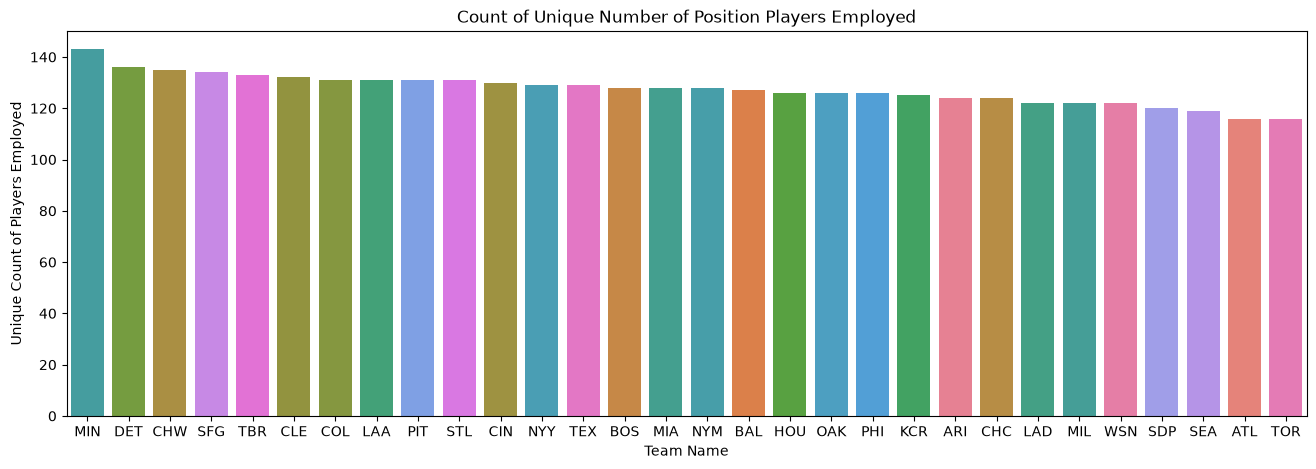

In [15]:
order = players_without_multiple["Team"].value_counts().index
plt.figure(figsize=(16, 5))
sns.countplot(data=players_without_multiple, x="Team", order=order, hue="Team")
plt.title("Count of Unique Number of Position Players Employed")
plt.xlabel("Team Name")
plt.ylabel("Unique Count of Players Employed")
plt.show()

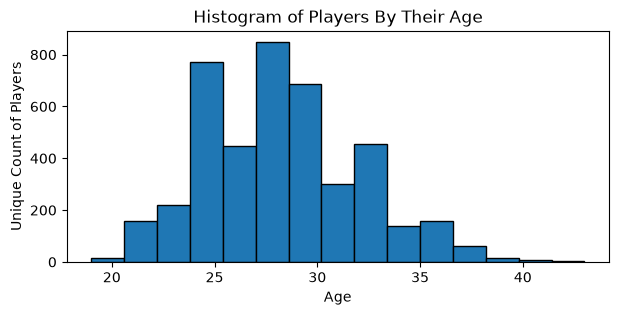

In [16]:
order1 = cleaned_baseball["Age"].value_counts().index
plt.figure(figsize=(7, 3))
plt.title("Histogram of Players By Their Age")
plt.hist(data=cleaned_baseball, x="Age", bins=15, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Unique Count of Players")
plt.show()

In [17]:
homers = pd.pivot_table(cleaned_baseball, index="Player", values="HR", aggfunc="sum")
top_1o_pivot = homers.nlargest(10, "HR")
print(top_1o_pivot)

                    HR
Player                
Nolan Arenado      313
Aaron Judge        311
Manny Machado      309
J.D. Martinez      284
Kyle Schwarber     284
Bryce Harper       281
Mike Trout         280
Paul Goldschmidt   279
Eugenio Suarez     272
Giancarlo Stanton  268


In [18]:
strikeouts = pd.pivot_table(cleaned_baseball, index="Player", values="SO", aggfunc="sum")
most_strikeout_prone = strikeouts.nlargest(10, "SO")
print(most_strikeout_prone)

                    SO
Player                
Eugenio Suarez    1551
Paul Goldschmidt  1441
J.D. Martinez     1362
Nick Castellanos  1343
Kyle Schwarber    1328
Tommy Pham        1312
Joey Gallo        1273
Paul DeJong       1232
Bryce Harper      1215
Christian Yelich  1178


In [19]:
allstar = cleaned_baseball[cleaned_baseball["All Star Appearance"] == True]

allstarappearance = pd.pivot_table(allstar, index="Player", values="All Star Appearance", aggfunc="sum")
most_all_stars = allstarappearance.nlargest(10, "All Star Appearance")
print(most_all_stars)

                 All Star Appearance
Player                              
Mike Trout                         8
Mookie Betts                       8
Nolan Arenado                      8
Jose Altuve                        7
Salvador Perez                     7
Aaron Judge                        6
Bryce Harper                       6
Freddie Freeman                    6
J.D. Martinez                      6
Jose Ramirez                       6


In [20]:
MVP = cleaned_baseball[cleaned_baseball["MVP"] == True]

MVPWins = pd.pivot_table(MVP, index="Player", values="MVP", aggfunc="sum")
most_mvps = MVPWins.nlargest(10, "MVP")
print(most_mvps)

                   MVP
Player                
Shohei Ohtani        3
Aaron Judge          2
Bryce Harper         2
Mike Trout           2
Christian Yelich     1
Cody Bellinger       1
Freddie Freeman      1
Giancarlo Stanton    1
Jose Abreu           1
Jose Altuve          1


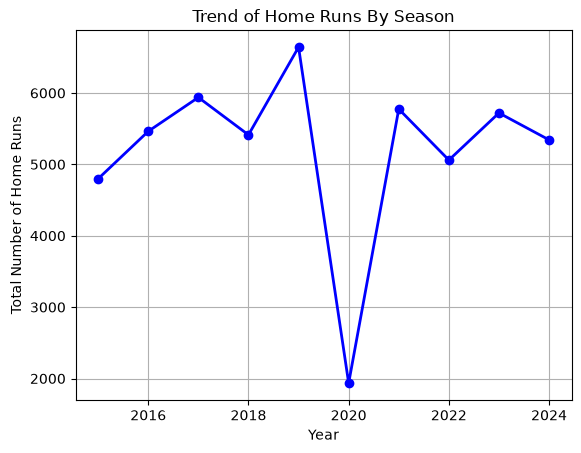

In [21]:
home_runs_totals = cleaned_baseball.groupby("Year")["HR"].sum()

home_runs_totals.plot(kind="line", marker="o", color="blue", linewidth=2)
plt.title("Trend of Home Runs By Season")
plt.xlabel("Year")
plt.ylabel("Total Number of Home Runs")
plt.grid(True)
plt.show()

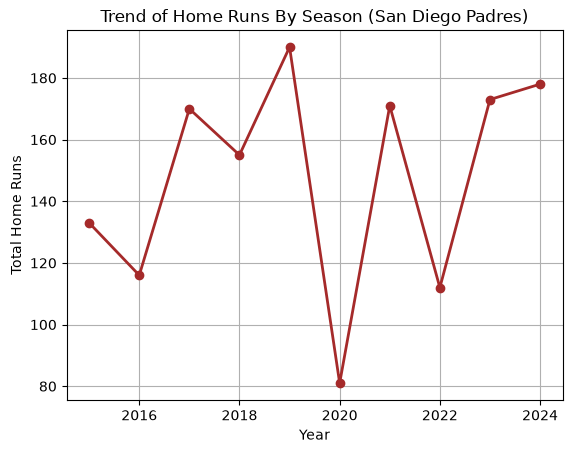

In [22]:
sandiegopadres = cleaned_baseball[cleaned_baseball["Team"] == "SDP"]
padres_homers = sandiegopadres.groupby("Year")["HR"].sum()

padres_homers.plot(kind="line", marker="o", color="brown", linewidth=2)
plt.title("Trend of Home Runs By Season (San Diego Padres)")
plt.xlabel("Year")
plt.ylabel("Total Home Runs")
plt.grid(True)
plt.show()

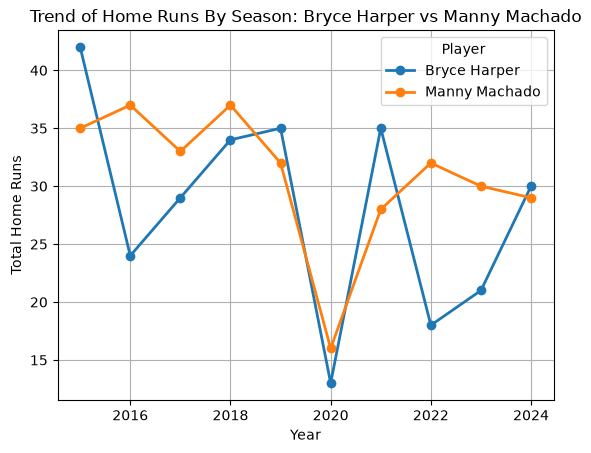

In [23]:
mannyandbryce = cleaned_baseball[cleaned_baseball["Player"].isin(["Manny Machado", "Bryce Harper"])]

home_runs = mannyandbryce.groupby(["Player", "Year"])["HR"].sum().unstack("Player")

home_runs.plot(kind="line", marker="o", linewidth=2)
plt.title("Trend of Home Runs By Season: Bryce Harper vs Manny Machado")
plt.xlabel("Year")
plt.ylabel("Total Home Runs")
plt.legend(title="Player")
plt.grid(True)
plt.show()

In [24]:
def parse_awards_complete(award_string):
    if pd.isna(award_string):
        return []
    
    awards_list = []
    for award in award_string.split(','):
        award = award.strip()
        
        if award == 'MVP-1':
            awards_list.append('MVP')
        elif award.startswith('MVP'):
            continue
        elif award == 'ROY-1':
            awards_list.append('ROY')
        elif award.startswith('ROY'):
            continue
        else:
            awards_list.append(award)
    
    return sorted(awards_list)

cleaned_baseball['awards'] = cleaned_baseball['Awards'].apply(parse_awards_complete)

In [25]:
award_winners = cleaned_baseball[
    cleaned_baseball['awards'].apply(
        lambda x: any(award in x for award in ['MVP', 'ROY', 'AS', 'GG', 'SS'])
    )
]

**What is the composition of awards won by mookie betters**

In [26]:
player = "Mookie Betts"

player_data = award_winners[award_winners["Player"] == player]

all_awards = []
for awards_list in player_data["awards"]:
    all_awards.extend(awards_list)

print(f"{player} - Award Composition:")
print(f"  MVP:        {all_awards.count('MVP')}")
print(f"  ROY:        {all_awards.count('ROY')}")
print(f"  All-Star:   {all_awards.count('AS')}")
print(f"  Gold Glove: {all_awards.count('GG')}")
print(f"  Slugger:    {all_awards.count('SS')}")
print(f"  {'─'*30}")
print(f"  Total:      {len(all_awards)}")

Mookie Betts - Award Composition:
  MVP:        1
  ROY:        0
  All-Star:   8
  Gold Glove: 6
  Slugger:    7
  ──────────────────────────────
  Total:      22


**Which Players Have Accumulated the most amount of awards**

In [27]:
top_10_players = award_winners.groupby("Player").size().sort_values(ascending=False).head(10)

total_awards = award_winners.groupby("Player")["awards"].apply(
    lambda x: sum(len(awards) for awards in x)
).sort_values(ascending=False).head(10)

print("\nTop 10 Players - Total Individual Awards:")
print(total_awards)


Top 10 Players - Total Individual Awards:
Player
Mookie Betts        22
Nolan Arenado       21
Mike Trout          16
Salvador Perez      15
Jose Altuve         15
Aaron Judge         13
Paul Goldschmidt    13
Bryce Harper        12
Shohei Ohtani       12
Jose Ramirez        11
Name: awards, dtype: int64


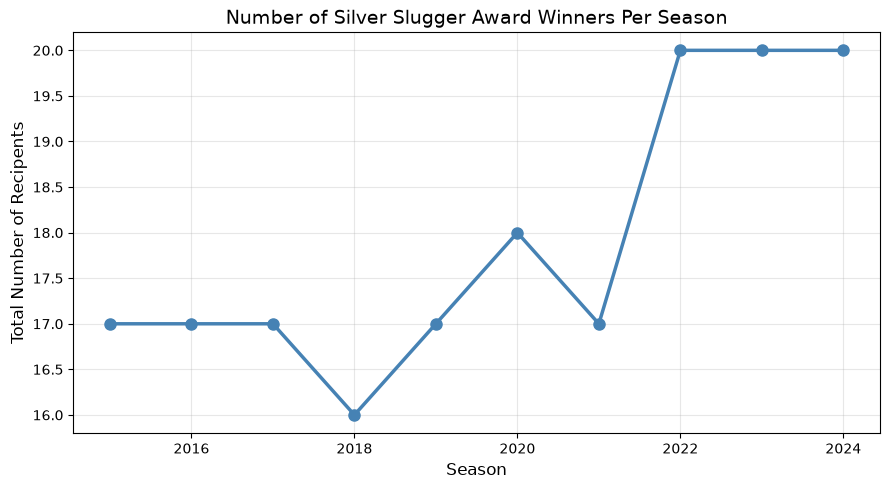

In [28]:
sliver_slugger = cleaned_baseball[cleaned_baseball["awards"].apply(lambda x: "SS" in x)]

ss_by_year = sliver_slugger.groupby("Year").size()

plt.figure(figsize=(9, 5))
plt.plot(ss_by_year.index, ss_by_year.values, marker='o', linewidth=2.5, markersize=8, color='steelblue')
plt.xlabel("Season", fontsize=12)
plt.ylabel("Total Number of Recipents", fontsize=12)
plt.title("Number of Silver Slugger Award Winners Per Season", fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

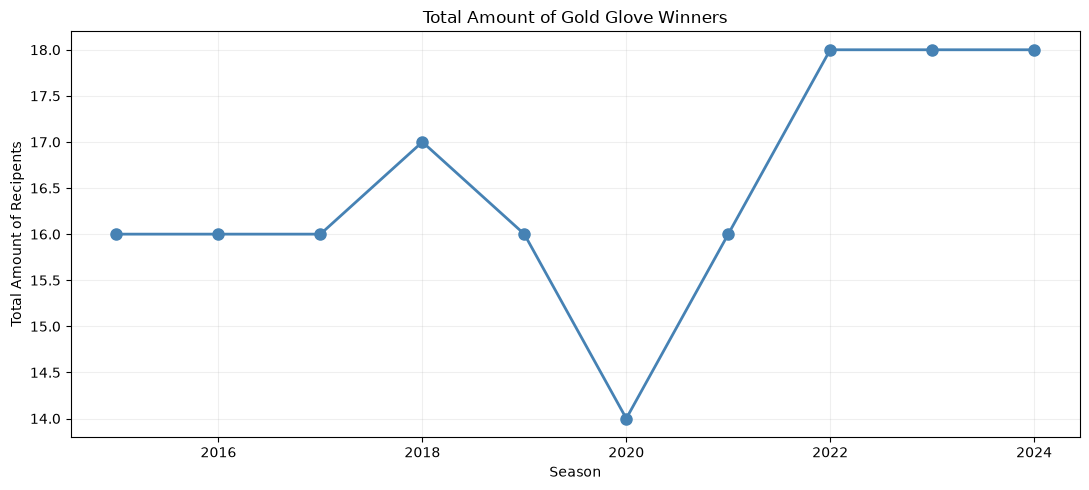

In [29]:
gold_glove = cleaned_baseball[cleaned_baseball["awards"].apply(lambda x: "GG" in x)]

gold_glove_by_year = gold_glove.groupby("Year").size()

plt.figure(figsize=(11, 5))
plt.plot(gold_glove_by_year.index, gold_glove_by_year.values, marker="o", linewidth=2.0, markersize=8, color="steelblue")
plt.title("Total Amount of Gold Glove Winners")
plt.ylabel("Total Amount of Recipents")
plt.xlabel("Season")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

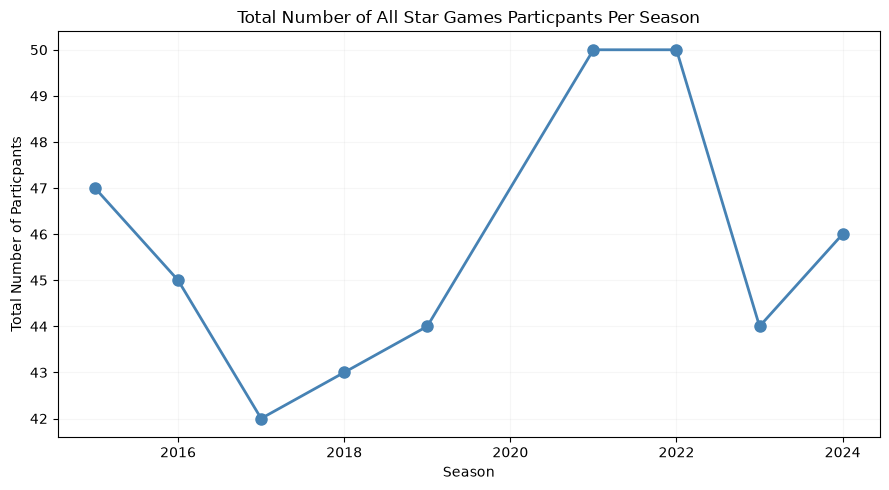

In [30]:
all_star = cleaned_baseball[cleaned_baseball["awards"].apply(lambda x: "AS" in x)]

all_star_by_year = all_star.groupby("Year").size()

plt.figure(figsize=(9, 5))
plt.plot(all_star_by_year.index, all_star_by_year.values, marker="o", linewidth=2, markersize=8, color="steelblue")
plt.xlabel("Season")
plt.ylabel("Total Number of Particpants")
plt.title("Total Number of All Star Games Particpants Per Season")
plt.grid(True, alpha=0.1)
plt.tight_layout()
plt.show()

In [31]:
cleaned_baseball[["G", "WAR"]].corr()

,G,WAR
G,1.000000,0.558849
WAR,0.558849,1.000000


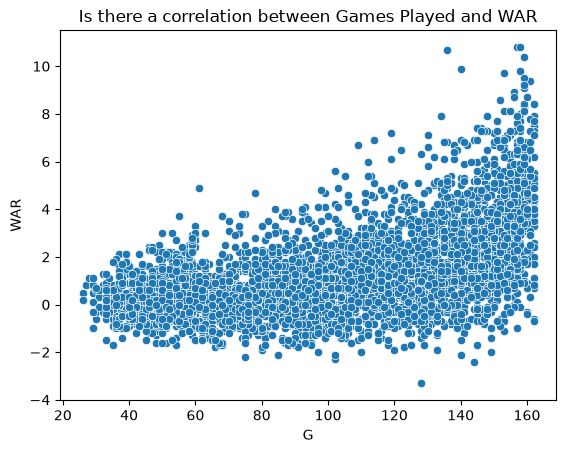

In [32]:
sns.scatterplot(data=cleaned_baseball, x="G", y="WAR")
plt.title("Is there a correlation between Games Played and WAR")
plt.show()

In [33]:
cleaned_baseball[["AB", "OBP"]].corr()

,AB,OBP
AB,1.000000,0.378338
OBP,0.378338,1.000000


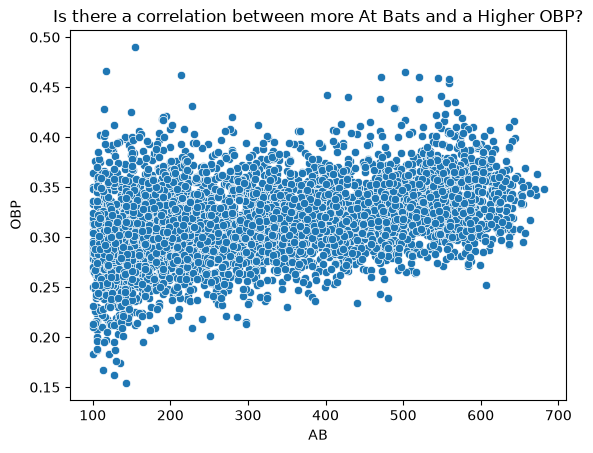

In [34]:
plt.title("Is there a correlation between more At Bats and a Higher OBP?")
sns.scatterplot(data=cleaned_baseball, x="AB", y="OBP")
plt.show()

In [35]:
cleaned_baseball[["BB", "OBP"]].corr()

,BB,OBP
BB,1.00000,0.60601
OBP,0.60601,1.00000


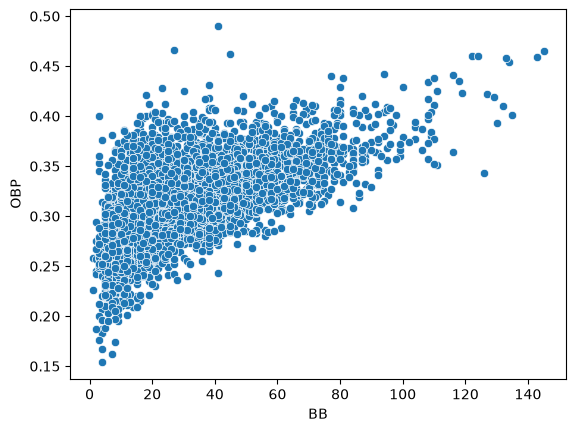

In [36]:
sns.scatterplot(data=cleaned_baseball, x="BB", y="OBP")
plt.show()

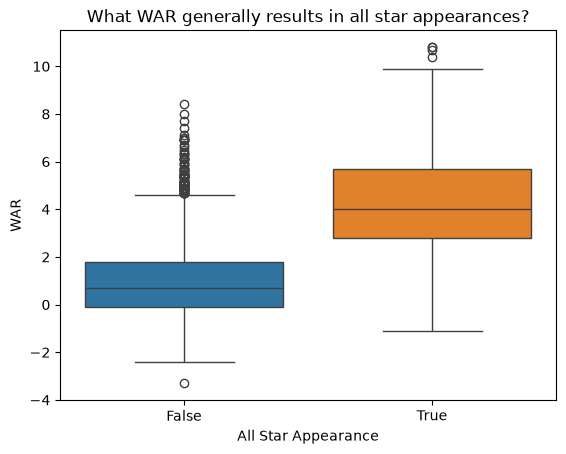

In [37]:
plt.title("What WAR generally results in all star appearances?")
sns.boxplot(data=cleaned_baseball, x="All Star Appearance", y="WAR", hue="All Star Appearance")
plt.legend().remove()
plt.show()

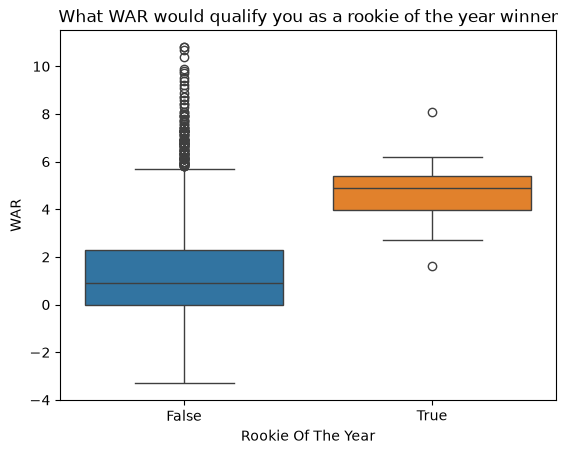

In [38]:
sns.boxplot(data=cleaned_baseball, x="Rookie Of The Year", y="WAR", hue="Rookie Of The Year")
plt.title("What WAR would qualify you as a rookie of the year winner")
plt.legend().remove()
plt.show()

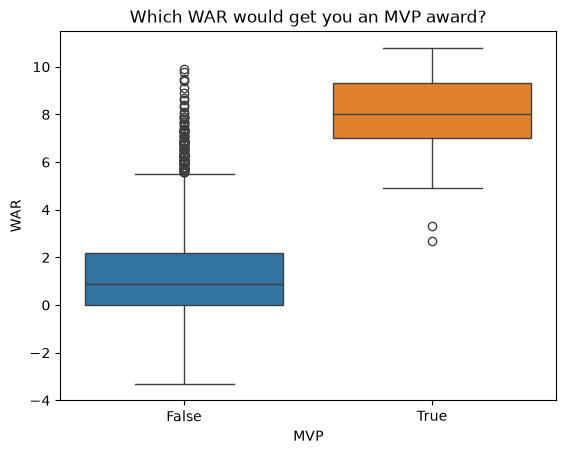

In [39]:
sns.boxplot(data=cleaned_baseball, x="MVP", y="WAR", hue="MVP")
plt.title("Which WAR would get you an MVP award?")
plt.legend().remove()
plt.show()

In [40]:
cleaned_baseball.head(5)

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,Year,Rookie Of The Year,All Star Appearance,Gold Glove,MVP,Sliver Slugger,Considered for Rookie Of The Year,Considered for MVP,Played For Multiple Teams,awards
0,A.J. Ellis,35,2TM,NL,-0.1,64,196,171,11,37,...,2016,False,False,False,False,False,False,False,True,[]
1,AJ Pollock,35,2TM,2LG,-0.7,54,144,133,15,22,...,2023,False,False,False,False,False,False,False,True,[]
2,Aaron Hicks,33,2TM,AL,0.5,93,312,269,44,68,...,2023,False,False,False,False,False,False,False,True,[]
3,Aaron Hill,34,2TM,2LG,1.5,125,429,378,48,99,...,2016,False,False,False,False,False,False,False,True,[]
4,Abraham Almonte,26,2TM,2LG,0.8,82,258,232,36,58,...,2015,False,False,False,False,False,False,False,True,[]


In [41]:
single_team = cleaned_baseball[cleaned_baseball["Played For Multiple Teams"] == False]
multiple_team = cleaned_baseball[cleaned_baseball["Played For Multiple Teams"] == True]

for stat in ["WAR", "R", "H", "2B", "3B", "HR", "RBI", "SB", "BB", "SO", "BA", "OBP", "SLG", "OPS", "OPS+", "TB", "GIDP"]:
    if stat in cleaned_baseball.columns:
        single_means = single_team[stat].mean()
        multi_means = multiple_team[stat].mean()
        
        print(f"\n{stat}:")
        print(f"  Single Team:     {single_means:.4f}")
        print(f"  Multiple Teams:  {multi_means:.4f}")
        print(f"  Difference:      {single_means - multi_means:.4f}")


WAR:
  Single Team:     1.4328
  Multiple Teams:  0.5498
  Difference:      0.8830

R:
  Single Team:     46.4872
  Multiple Teams:  37.3319
  Difference:      9.1553

H:
  Single Team:     86.8925
  Multiple Teams:  71.4397
  Difference:      15.4529

2B:
  Single Team:     17.3316
  Multiple Teams:  14.1961
  Difference:      3.1355

3B:
  Single Team:     1.6389
  Multiple Teams:  1.2500
  Difference:      0.3889

HR:
  Single Team:     12.4419
  Multiple Teams:  9.7177
  Difference:      2.7243

RBI:
  Single Team:     44.6182
  Multiple Teams:  36.1034
  Difference:      8.5148

SB:
  Single Team:     5.6710
  Multiple Teams:  4.5409
  Difference:      1.1301

BB:
  Single Team:     32.4744
  Multiple Teams:  26.9289
  Difference:      5.5455

SO:
  Single Team:     81.5479
  Multiple Teams:  74.4009
  Difference:      7.1470

BA:
  Single Team:     0.2483
  Multiple Teams:  0.2326
  Difference:      0.0157

OBP:
  Single Team:     0.3176
  Multiple Teams:  0.3017
  Difference:  

In [42]:
print(multiple_team.shape)

(464, 42)


In [43]:
single_war = single_team["WAR"].dropna()
multi_war = multiple_team["WAR"].dropna()

print(f"\nSingle Team WAR:     Mean={single_war.mean():.3f}, Std={single_war.std():.3f}, N={len(single_war)}")
print(f"Multiple Teams WAR:  Mean={multi_war.mean():.3f}, Std={multi_war.std():.3f}, N={len(multi_war)}")

from scipy import stats
t_stat, p_value = stats.ttest_ind(single_war, multi_war)

print(f"\nNull Hypothesis (H0): No difference in WAR between groups")
print(f"Alternative Hypothesis (H1): Single-team players have higher WAR")

print(f"\nTest Results:")
print(f"  t-statistic:        {t_stat:.4f}")
print(f"  p-value (two-tailed): {p_value:.2e}")
print(f"  p-value (one-tailed): {p_value/2:.2e}")

print("\n3. STATISTICAL SIGNIFICANCE")
print("-" * 80)

alpha = 0.05
if p_value < alpha:
    print(f"\n✓ RESULT: STATISTICALLY SIGNIFICANT (p = {p_value:.2e} < {alpha})")
    print(f"\nWe REJECT the null hypothesis.")
    print(f"There IS a significant difference in WAR between single-team")
    print(f"and multi-team players during the season.")
else:
    print(f"\n✗ RESULT: NOT STATISTICALLY SIGNIFICANT (p = {p_value:.4f} >= {alpha})")
    print(f"\nWe FAIL TO REJECT the null hypothesis.")
    print(f"There is NO significant difference in WAR between single-team")
    print(f"and multi-team players during the season.")

    print("\n4. EFFECT SIZE (COHEN'S D)")
    print("-" * 80)

n1 = len(single_war)
n2 = len(multi_war)

# Corrected pooled standard deviation
pooled_std = np.sqrt(
    ((n1 - 1) * single_war.std()**2 + 
     (n2 - 1) * multi_war.std()**2) / 
    (n1 + n2 - 2)
)

# Cohen's d
cohens_d = (single_war.mean() - multi_war.mean()) / pooled_std

print(f"\nPooled Standard Deviation: {pooled_std:.4f}")
print(f"Cohen's d:                {cohens_d:.4f}")

# Interpret effect size
if abs(cohens_d) < 0.2:
    effect_interpretation = "Negligible"
elif abs(cohens_d) < 0.5:
    effect_interpretation = "Small"
elif abs(cohens_d) < 0.8:
    effect_interpretation = "Medium"
else:
    effect_interpretation = "Large"

print(f"Effect Size Interpretation: {effect_interpretation}")


Single Team WAR:     Mean=1.433, Std=1.905, N=3824
Multiple Teams WAR:  Mean=0.550, Std=1.309, N=464

Null Hypothesis (H0): No difference in WAR between groups
Alternative Hypothesis (H1): Single-team players have higher WAR

Test Results:
  t-statistic:        9.7082
  p-value (two-tailed): 4.69e-22
  p-value (one-tailed): 2.34e-22

3. STATISTICAL SIGNIFICANCE
--------------------------------------------------------------------------------

✓ RESULT: STATISTICALLY SIGNIFICANT (p = 4.69e-22 < 0.05)

We REJECT the null hypothesis.
There IS a significant difference in WAR between single-team
and multi-team players during the season.

Pooled Standard Deviation: 1.8503
Cohen's d:                0.4773
Effect Size Interpretation: Small


**Which Teams Are Not Good and Which Teams are Good**

In [44]:
single_team_only = cleaned_baseball[~cleaned_baseball['Team'].str.contains('TM', na=False)]

In [45]:
team_impact = single_team_only.groupby("Team").agg({
    "WAR": ["mean", "median", "std"],
    "Player": "nunique"
}).round(3)

team_impact.columns = ["AVG_WAR", "Median_WAR", "std_WAR", "Unique_Players"]
team_impact = team_impact.sort_values("AVG_WAR", ascending=False)

print("\nTeam Impact on WAR (Top and Bottom Teams)")
print("="*80)
print("\nTOP 10 Teams (Career-Saving):")
print(team_impact.head(10))

print("\nBOTTOM 10 Teams (Career-Ruining):")
print(team_impact.tail(10))


Team Impact on WAR (Top and Bottom Teams)

TOP 10 Teams (Career-Saving):
      AVG_WAR  Median_WAR  std_WAR  Unique_Players
Team                                              
HOU     2.453        2.05    2.223              44
LAD     2.331        1.85    2.070              45
TOR     1.880        1.45    1.854              48
BOS     1.843        1.35    2.294              52
CHC     1.827        1.60    1.879              48
ATL     1.783        1.10    2.137              44
NYY     1.766        1.20    2.214              53
STL     1.723        1.40    1.902              51
SEA     1.695        1.30    1.835              62
TBR     1.651        1.40    1.625              68

BOTTOM 10 Teams (Career-Ruining):
      AVG_WAR  Median_WAR  std_WAR  Unique_Players
Team                                              
WSN     1.256        0.70    1.921              65
SFG     1.181        0.80    1.583              57
PHI     1.153        0.85    1.635              51
COL     1.104        0.7

**Which Features Are Most Indicative of a Players War Value**
- The base model returns an R2 Score of 80.61%

In [46]:
cleaned_baseball.head(5)

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,Year,Rookie Of The Year,All Star Appearance,Gold Glove,MVP,Sliver Slugger,Considered for Rookie Of The Year,Considered for MVP,Played For Multiple Teams,awards
0,A.J. Ellis,35,2TM,NL,-0.1,64,196,171,11,37,...,2016,False,False,False,False,False,False,False,True,[]
1,AJ Pollock,35,2TM,2LG,-0.7,54,144,133,15,22,...,2023,False,False,False,False,False,False,False,True,[]
2,Aaron Hicks,33,2TM,AL,0.5,93,312,269,44,68,...,2023,False,False,False,False,False,False,False,True,[]
3,Aaron Hill,34,2TM,2LG,1.5,125,429,378,48,99,...,2016,False,False,False,False,False,False,False,True,[]
4,Abraham Almonte,26,2TM,2LG,0.8,82,258,232,36,58,...,2015,False,False,False,False,False,False,False,True,[]


In [47]:
columns = cleaned_baseball[["Age", "G", "PA", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "CS", "BB", "SO", "OPS+", "TB", "GIDP", "HBP", "SH", "SF", "IBB", "Rbat+", "Rookie Of The Year", "All Star Appearance", "Gold Glove", "MVP", "Sliver Slugger", "Considered for Rookie Of The Year", "Considered for MVP", "Played For Multiple Teams", "WAR"]]

In [48]:
columns.head(5)

,Age,G,PA,AB,R,H,2B,3B,HR,RBI,...,Rbat+,Rookie Of The Year,All Star Appearance,Gold Glove,MVP,Sliver Slugger,Considered for Rookie Of The Year,Considered for MVP,Played For Multiple Teams,WAR
0,35,64,196,171,11,37,8,0,2,22,...,62,False,False,False,False,False,False,False,True,-0.1
1,35,54,144,133,15,22,4,0,5,15,...,48,False,False,False,False,False,False,False,True,-0.7
2,33,93,312,269,44,68,9,1,8,36,...,106,False,False,False,False,False,False,False,True,0.5
3,34,125,429,378,48,99,14,0,10,38,...,88,False,False,False,False,False,False,False,True,1.5
4,26,82,258,232,36,58,12,5,5,24,...,86,False,False,False,False,False,False,False,True,0.8


In [55]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import pandas as pd

**Which models are the most effective and least effective at predicting R2 Score**
- Linear Regression
- Ridge 
- Lasso 
- Random Forest 
- XG Boost
- LightGBM

In [61]:
features = [
    "Age", "G", "PA", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "CS", "BB", "SO", "OPS+", "TB", "GIDP", "HBP", "SH", "SF", "IBB", "Rbat+", "Rookie Of The Year", "All Star Appearance", "Gold Glove", "MVP", "Sliver Slugger", "Considered for Rookie Of The Year", "Considered for MVP", "Played For Multiple Teams" 
]

categorical_columns = ["Rookie Of The Year", "All Star Appearance", "Gold Glove", "MVP", "Sliver Slugger", "Considered for Rookie Of The Year", "Considered for MVP", "Played For Multiple Teams"]
numerical_columns = ["Age", "G", "PA", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "CS", "BB", "SO", "OPS+", "TB", "GIDP", "HBP", "SH", "SF", "IBB", "Rbat+"]


def make_preprocessor(scale_numeric=False):
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_columns),
            ("num", numeric_step, numerical_columns)
        ]
    )
    
def evaluate_model(df, name, model, scale_numeric=False, random_state=43):
    X = df[features]
    y = df["WAR"]
    
    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor(scale_numeric)),
        ("model", model)
    ])

    kf = KFold(n_splits=5, shuffle=True, random_state=random_state)
    cv_r2 = cross_val_score(pipeline, X, y, cv=kf, scoring="r2")
    cv_rmse = cross_val_score(pipeline, X, y, cv=kf, scoring="neg_root_mean_squared_error")
    cv_mae = cross_val_score(pipeline, X, y, cv=kf, scoring="neg_mean_absolute_error")
    
    return {
        "Dataset": name, 
        "CV_RMSE": -cv_rmse.mean(),
        "CV_MAE": -cv_mae.mean(),
        "CV_R2": cv_r2.mean()
    }

def run_all_models(df):
    model_configs = [
        ("Linear Regression", LinearRegression(), False),
        ("Ridge", Ridge(alpha=1.0, random_state=43), True),
        ("Lasso", Lasso(alpha=0.01, random_state=43), True),
        ("Random Forest", RandomForestRegressor(n_estimators=300, max_depth=None, random_state=43, n_jobs=-1), False),
        ("XGBoost", XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=43, n_jobs=-1), False),
        ("LightGBM",LGBMRegressor(n_estimators=300, max_depth=-1, learning_rate=0.05, random_state=43, n_jobs=-1), False),

    ]
    
    results = [
        evaluate_model(df, name, model, scale_numeric=scale)
        for name, model, scale in model_configs
    ]
    return pd.DataFrame(results)

model_df = columns[features + ["WAR"]]
results_df = run_all_models(model_df)
print(results_df.round(4).to_string(index=False))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001449 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2235
[LightGBM] [Info] Number of data points in the train set: 3430, number of used features: 28
[LightGBM] [Info] Start training from score 1.317493


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001797 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2233
[LightGBM] [Info] Number of data points in the train set: 3430, number of used features: 28
[LightGBM] [Info] Start training from score 1.334227


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000861 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2216
[LightGBM] [Info] Number of data points in the train set: 3430, number of used features: 28
[LightGBM] [Info] Start training from score 1.329417


...

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001682 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2229
[LightGBM] [Info] Number of data points in the train set: 3431, number of used features: 28
[LightGBM] [Info] Start training from score 1.348412


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001677 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2230
[LightGBM] [Info] Number of data points in the train set: 3431, number of used features: 28
[LightGBM] [Info] Start training from score 1.356776
          Dataset  CV_RMSE  CV_MAE  CV_R2
Linear Regression   0.8227  0.6244 0.8061
            Ridge   0.8228  0.6246 0.8061
            Lasso   0.8383  0.6415 0.7987
    Random Forest   0.8176  0.6202 0.8083
          XGBoost   0.8009  0.6076 0.8162
         LightGBM   0.8018  0.6048 0.8158


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


**Optimize the XGBoost Model**

-Randomized Grid Searh CV bumps R2 score up to 82.1

In [65]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from scipy.stats import uniform, randint
from xgboost import XGBRegressor 

X = model_df[features]
y = model_df["WAR"]

preprocessor = make_preprocessor(scale_numeric=False)

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(random_state=43, n_jobs=-1))
])

param_dist = {
    "model__n_estimators": randint(100, 800),
    "model__max_depth": randint(3, 8),
    "model__learning_rate": uniform(0.01, 0.19),   
    "model__subsample": uniform(0.6, 0.4),           
    "model__colsample_bytree": uniform(0.6, 0.4),     
    "model__min_child_weight": randint(1, 10),
    "model__reg_alpha": uniform(0, 1),                
    "model__reg_lambda": uniform(0.5, 2.5),          
    "model__gamma": uniform(0, 0.5),
}

kf = KFold(n_splits=5, shuffle=True, random_state=43)

search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_dist,
    n_iter=100, 
    scoring="r2",
    cv=kf,
    random_state=43,
    n_jobs=-1,
    verbose=1
)

search.fit(X, y)

print("Best CV R2:", search.best_score_)
print("Best params:", search.best_params_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best CV R2: 0.8212954770234585
Best params: {'model__colsample_bytree': np.float64(0.669902971193875), 'model__gamma': np.float64(0.37551727537234386), 'model__learning_rate': np.float64(0.03067702966710601), 'model__max_depth': 5, 'model__min_child_weight': 3, 'model__n_estimators': 192, 'model__reg_alpha': np.float64(0.8189792026548813), 'model__reg_lambda': np.float64(1.155573839633841), 'model__subsample': np.float64(0.6071590317738705)}


**Check for overfitting**

In [66]:
results = pd.DataFrame(search.cv_results_)
top5 = results.sort_values("mean_test_score", ascending=False).head(5)
print(top5[["mean_test_score", "std_test_score", "params"]])

    mean_test_score  std_test_score  \
43         0.821295        0.010627   
79         0.821275        0.011786   
65         0.821117        0.010716   
33         0.820995        0.010754   
86         0.820980        0.012694   

                                               params  
43  {'model__colsample_bytree': 0.669902971193875,...  
79  {'model__colsample_bytree': 0.8245616804303462...  
65  {'model__colsample_bytree': 0.6863774694575653...  
33  {'model__colsample_bytree': 0.6250382883171658...  
86  {'model__colsample_bytree': 0.6123598220511288...  


**Does the performance of the XGBBoost Model improve with feature optimiation**
- no the model performs slighltly worse with feature optimization

In [71]:
from sklearn.inspection import permutation_importance

In [73]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=43)

xgb_pipeline.fit(X_train, y_train)

perm_result = permutation_importance(
    xgb_pipeline, X_test, y_test,
    scoring="r2",
    n_repeats=20,
    random_state=43,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": features,
    "r2_drop_mean": perm_result.importances_mean,
    "r2_drop_std": perm_result.importances_std
}).sort_values("r2_drop_mean", ascending=False)

print(perm_df.to_string(index=False))

                          feature  r2_drop_mean  r2_drop_std
                            Rbat+      0.286290     0.019059
                                R      0.206120     0.009257
               Considered for MVP      0.041572     0.003832
                                H      0.037311     0.004636
                               2B      0.034745     0.005380
                             OPS+      0.027293     0.004280
                               SB      0.022430     0.005807
                               PA      0.018859     0.004423
                       Gold Glove      0.018364     0.004534
                               HR      0.018153     0.002266
                                G      0.016526     0.004088
                               SH      0.011415     0.002667
                               SO      0.010200     0.002352
                               TB      0.010105     0.003772
                               AB      0.008902     0.002844
                        

In [79]:
keep_features = [
    "Rbat+", "R", "Considered for MVP", "H", "2B", "OPS+", "SB", "PA",
    "Gold Glove", "HR", "G", "SH", "SO", "TB", "AB", "RBI",
    "All Star Appearance", "GIDP", "Age", "BB"
]

keep_categorical = ["Considered for MVP", "Gold Glove", "All Star Appearance"]
keep_numerical = [f for f in keep_features if f not in keep_categorical]

def make_preprocessor_trimmed(cat_cols, num_cols, scale_numeric=False):
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
            ("num", numeric_step, num_cols)
        ]
    )

def evaluate_xgboost_trimmed(df, feature_list, cat_cols, num_cols,
                              name="XGBoost (trimmed)", random_state=43,
                              model_params=None):
    X = df[feature_list]
    y = df["WAR"]

    if model_params is None:
        model_params = dict(
            n_estimators=300, max_depth=4, learning_rate=0.05,
            random_state=random_state, n_jobs=-1
        )

    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor_trimmed(cat_cols, num_cols)),
        ("model", XGBRegressor(**model_params))
    ])

    kf = KFold(n_splits=5, shuffle=True, random_state=random_state)
    cv_r2 = cross_val_score(pipeline, X, y, cv=kf, scoring="r2")
    cv_rmse = cross_val_score(pipeline, X, y, cv=kf, scoring="neg_root_mean_squared_error")
    cv_mae = cross_val_score(pipeline, X, y, cv=kf, scoring="neg_mean_absolute_error")
    return {
        "Dataset": name,
        "CV_RMSE": -cv_rmse.mean(),
        "CV_MAE": -cv_mae.mean(),
        "CV_R2": cv_r2.mean()
    }

keep_results = evaluate_xgboost_trimmed(
    model_df, keep_features, keep_categorical, keep_numerical,
    name="XGBoost (keep features)"
)
print(pd.DataFrame([keep_results]).round(4).to_string(index=False))

                Dataset  CV_RMSE  CV_MAE  CV_R2
XGBoost (keep features)   0.8067  0.6128 0.8136


**XGBoost**
XGBoost Base: 0.8162 
XGBoost Base + Randomized Grid Search: 0.821
XGBoost Trimmed Features + K FOld Cross Validation 0.8136